# Mission 01: A Taxi Batch Pipeline at Scale

The city's mobility team receives the full monthly taxi export (about 3 million trips per month) and wants two
"gold" tables every morning: revenue per borough per day, and demand per zone and hour. Build the batch pipeline in
Spark, make it correct, and tune it with measurements instead of guesses.

**Lessons used:** 01 (architecture), 02 (plans), 03 (partitioning and the shuffle), 04 (joins), 10 (tuning).

**Data:** NYC yellow taxi trips, January and February 2024, and the taxi zone lookup table.

**Services:** none (Spark runs locally in the notebook).

In [1]:
import shutil
import sys
import tempfile
import time
import warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import requests
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

sys.path.insert(0, str(Path.cwd().parent.parent / "tools"))
import datasets                                   # course helper: pinned datasets

warnings.filterwarnings("ignore", message=".*pandas >= 3.0.0.*")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
WORK = Path(tempfile.gettempdir()) / "fzth-m13" / "mission01"
shutil.rmtree(WORK, ignore_errors=True); WORK.mkdir(parents=True)
RAW = [str(datasets.taxi("2024-01")), str(datasets.taxi("2024-02"))]
ZONES = str(datasets.fetch("taxi_zone_lookup.csv"))

spark = (SparkSession.builder.master("local[4]").appName("m13-mission01")
         .config("spark.driver.memory", "1500m").config("spark.sql.shuffle.partitions", "8")
         .config("spark.ui.showConsoleProgress", "false").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "| UI:", spark.sparkContext.uiWebUrl, "| work dir:", WORK)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/17 23:10:20 WARN Utils: Your hostname, Muhammet, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/17 23:10:20 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/17 23:10:21 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.0 | UI: http://10.255.255.254:4040 | work dir: /tmp/fzth-m13/mission01


## Tasks

1. **Clean.** Read both months. Keep trips with a pickup inside January–February 2024, `trip_distance` in (0, 100],
   `total_amount` in [0, 1000], and a known pickup zone (1–263). Report how many rows each rule removes.
2. **Enrich.** Join the zone lookup (borough, zone name) and add `pickup_date` and `pickup_hour`. Show in the plan
   which join strategy Spark chose and why.
3. **Gold tables.** Build `daily_borough_revenue` (date, borough, trips, revenue, average tip %) and
   `zone_hour_demand` (zone, hour of day, weekday/weekend, average trips per day). Write the first one as Parquet,
   partitioned by month; report the number of files and bytes.
4. **Tune.** Time the gold build with (a) 200 shuffle partitions and AQE off, (b) 8 shuffle partitions, AQE off,
   (c) AQE on. Report time, number of tasks and shuffle bytes from the Spark REST API, and choose a setting.
5. **Verify.** Recompute `daily_borough_revenue` with DuckDB SQL directly on the Parquet files with the same rules.
   The two results must be equal (trips exactly, revenue within one cent).
6. **Explain.** Five sentences for the mobility team: what the pipeline guarantees, which setting you chose and why,
   and what would change on a real cluster with 5 years of data.

## Solution

### 1. Clean, with a count per rule

In [2]:
raw = spark.read.parquet(*RAW)
rules = [
    ("pickup in Jan-Feb 2024", (F.col("tpep_pickup_datetime") >= "2024-01-01") & (F.col("tpep_pickup_datetime") < "2024-03-01")),
    ("trip_distance in (0, 100]", (F.col("trip_distance") > 0) & (F.col("trip_distance") <= 100)),
    ("total_amount in [0, 1000]", F.col("total_amount").between(0, 1000)),
    ("known pickup zone (1-263)", F.col("PULocationID").between(1, 263)),
]
df, counts = raw, [("raw rows", raw.count())]
for name, cond in rules:
    df = df.filter(cond)
    counts.append((name, df.count()))
steps = pd.DataFrame(counts, columns=["after rule", "rows"])
steps["removed"] = (-steps.rows.diff()).fillna(0).astype(int)
print(steps.to_string(index=False))
clean = df.select("tpep_pickup_datetime", "PULocationID", "trip_distance", "fare_amount", "tip_amount", "total_amount")

               after rule    rows  removed
                 raw rows 5972150        0
   pickup in Jan-Feb 2024 5972131       19
trip_distance in (0, 100] 5843405   128726
total_amount in [0, 1000] 5778469    64936
known pickup zone (1-263) 5758520    19949


### 2. Enrich with the zone lookup

In [3]:
zones = spark.read.csv(ZONES, header=True, inferSchema=True).select(
    F.col("LocationID").alias("PULocationID"), "Borough", "Zone")
trips = (clean.join(zones, "PULocationID")
         .withColumn("pickup_date", F.to_date("tpep_pickup_datetime"))
         .withColumn("pickup_hour", F.hour("tpep_pickup_datetime")))
plan = trips._jdf.queryExecution().executedPlan().toString()
print("join strategy:", "BroadcastHashJoin" if "BroadcastHashJoin" in plan else "SortMergeJoin" if "SortMergeJoin" in plan else plan[:200])
print(f"zones table: {zones.count()} rows -> far below spark.sql.autoBroadcastJoinThreshold "
      f"({spark.conf.get('spark.sql.autoBroadcastJoinThreshold')}), so Spark copies it to every task instead of shuffling 6M trips")

join strategy: BroadcastHashJoin


zones table: 265 rows -> far below spark.sql.autoBroadcastJoinThreshold (10485760b), so Spark copies it to every task instead of shuffling 6M trips


### 3. Gold tables

In [4]:
def build_gold(df):
    daily = (df.groupBy("pickup_date", "Borough")
             .agg(F.count("*").alias("trips"), F.round(F.sum("total_amount"), 2).alias("revenue"),
                  # ANSI mode (Spark 4 default) raises on x / 0: try_divide returns NULL instead
                  F.round(100 * F.try_divide(F.sum("tip_amount"), F.sum("fare_amount")), 2).alias("avg_tip_pct")))
    per_day = (df.withColumn("day_type", F.when(F.dayofweek("pickup_date").isin(1, 7), "weekend").otherwise("weekday"))
               .groupBy("Zone", "pickup_hour", "day_type", "pickup_date").count())
    demand = (per_day.groupBy("Zone", "pickup_hour", "day_type")
              .agg(F.round(F.avg("count"), 1).alias("avg_trips_per_day")))
    return daily, demand

daily, demand = build_gold(trips)
out = WORK / "daily_borough_revenue"
daily.withColumn("month", F.date_format("pickup_date", "yyyy-MM")).write.partitionBy("month").parquet(str(out))
files = list(out.rglob("*.parquet"))
print(f"daily_borough_revenue: {daily.count()} rows -> {len(files)} files, {sum(f.stat().st_size for f in files)/1024:.0f} KiB")
print("partitions:", sorted(p.name for p in out.iterdir() if p.is_dir()))
print(demand.orderBy(F.desc("avg_trips_per_day")).limit(5).toPandas().to_string(index=False))

daily_borough_revenue: 335 rows -> 2 files, 9 KiB
partitions: ['month=2024-01', 'month=2024-02']


          Zone  pickup_hour day_type  avg_trips_per_day
  East Village            1  weekend              563.4
  East Village            0  weekend              546.6
Midtown Center           18  weekday              519.5
Midtown Center           17  weekday              488.6
  West Village            0  weekend              466.4


### 4. Tune with measurements

                setting  seconds  tasks  shuffle MB
200 partitions, AQE off     10.1    610        14.6
  8 partitions, AQE off      2.7     34         6.2
 200 partitions, AQE on      2.3     16         7.2


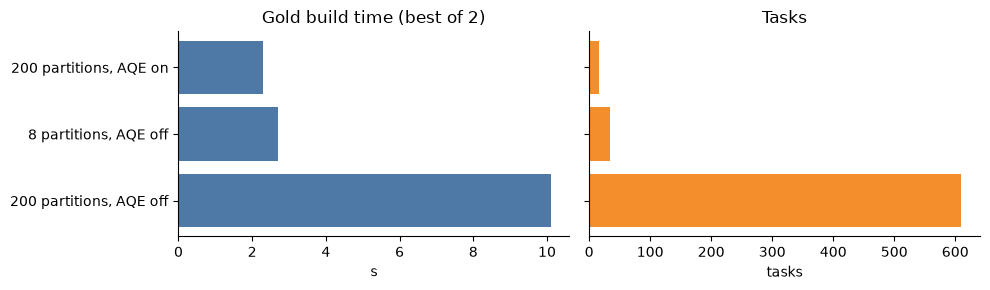

In [5]:
PORT = spark.sparkContext.uiWebUrl.rsplit(":", 1)[1]           # the reported host can be a WSL address: use localhost
API = f"http://localhost:{PORT}/api/v1/applications/{spark.sparkContext.applicationId}"

def measured(label: str, shuffle_partitions: int, aqe: bool) -> dict:
    spark.conf.set("spark.sql.shuffle.partitions", str(shuffle_partitions))
    spark.conf.set("spark.sql.adaptive.enabled", str(aqe).lower())
    best = None
    for _ in range(2):
        group = f"tune-{label}-{time.time_ns()}"
        spark.sparkContext.setJobGroup(group, label)
        t0 = time.perf_counter()
        d, m = build_gold(trips)
        d.write.mode("overwrite").parquet(str(WORK / "tune_daily")); m.write.mode("overwrite").parquet(str(WORK / "tune_demand"))
        elapsed = time.perf_counter() - t0
        jobs = [j for j in requests.get(f"{API}/jobs", timeout=60).json() if j.get("jobGroup") == group]
        stage_ids = {s for j in jobs for s in j["stageIds"]}
        stages = [a for sid in stage_ids for a in requests.get(f"{API}/stages/{sid}", timeout=60).json()
                  if a["status"] == "COMPLETE"]                       # skipped stages have no COMPLETE attempt
        run = {"setting": label, "seconds": round(elapsed, 1), "tasks": sum(s["numCompleteTasks"] for s in stages),
               "shuffle MB": round(sum(s["shuffleWriteBytes"] for s in stages) / 1e6, 1)}
        best = run if best is None or run["seconds"] < best["seconds"] else best
    spark.sparkContext.setJobGroup("", "")
    return best

tuning = pd.DataFrame([measured("200 partitions, AQE off", 200, False),
                       measured("8 partitions, AQE off", 8, False),
                       measured("200 partitions, AQE on", 200, True)])
print(tuning.to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].barh(tuning.setting, tuning.seconds, color="#4E79A7"); ax[0].set(title="Gold build time (best of 2)", xlabel="s")
ax[1].barh(tuning.setting, tuning.tasks, color="#F28E2B"); ax[1].set(title="Tasks", xlabel="tasks")
ax[1].set_yticklabels([])
plt.tight_layout(); plt.show()

### 5. Verify with DuckDB

In [6]:
files = ", ".join(f"'{p}'" for p in RAW)
ref = duckdb.sql(f"""
    SELECT CAST(t.tpep_pickup_datetime AS DATE) AS pickup_date, z.Borough, count(*) AS trips,
           round(sum(t.total_amount), 2) AS revenue
    FROM read_parquet([{files}]) t JOIN read_csv_auto('{ZONES}') z ON z.LocationID = t.PULocationID
    WHERE t.tpep_pickup_datetime >= '2024-01-01' AND t.tpep_pickup_datetime < '2024-03-01'
      AND t.trip_distance > 0 AND t.trip_distance <= 100 AND t.total_amount BETWEEN 0 AND 1000
      AND t.PULocationID BETWEEN 1 AND 263
    GROUP BY 1, 2""").df()
got = spark.read.parquet(str(out)).select("pickup_date", "Borough", "trips", "revenue").toPandas()
for frame in (ref, got):                            # DuckDB returns datetime64, Spark returns datetime.date objects
    frame["pickup_date"] = pd.to_datetime(frame.pickup_date)
cmp = ref.merge(got, on=["pickup_date", "Borough"], how="outer", suffixes=("_duckdb", "_spark"), indicator=True)
print("rows:", len(ref), "(DuckDB) vs", len(got), "(Spark) | only in one engine:", int((cmp._merge != "both").sum()))
print("trips equal:", bool((cmp.trips_duckdb == cmp.trips_spark).all()),
      "| max revenue difference:", round(float((cmp.revenue_duckdb - cmp.revenue_spark).abs().max()), 4))
spark.stop()

rows: 335 (DuckDB) vs 335 (Spark) | only in one engine: 0
trips equal: True | max revenue difference: 0.0


### 6. Explanation for the mobility team

1. Every removed row is counted per rule, so the gold tables state exactly which trips they exclude and why.
2. Spark and DuckDB computed the same daily revenue per borough independently, which checks the cleaning and the join.
3. On this data the shuffle is small, so 200 shuffle partitions mostly create task overhead (10.1 s, 610 tasks).
   8 partitions (2.7 s) or AQE (2.3 s, merges small partitions at run time) are better; AQE needs no manual number.
4. The zone table is tiny, so Spark broadcasts it and never shuffles the trips for the join.
5. On a cluster with five years of data (about 30 times more), the shuffle grows, and AQE still adapts the partition
   count. Partition the output by month, so that daily jobs rewrite only one partition.

## Submission Checklist

- [ ] Every cleaning rule has a row count; nothing is dropped silently.
- [ ] The join strategy is shown in a plan, not assumed.
- [ ] The tuning table comes from measurements (time, tasks, shuffle bytes).
- [ ] Spark and DuckDB give the same gold table.

A solution is in `01-Taxi-Batch-Pipeline-at-Scale-solution.ipynb`. Try the mission first.